# Complexity-05b — La permanente, frontière quantique : BosonSampling

[Source Python](Complexity-05b-AaronsonArkhipov-PermanenteBosonSampling-Python.ipynb) · [Index](README.md) · [05 — Compter est plus dur que vérifier](Complexity-05-CountingHarder-Permanent-Python.ipynb) · [06 — Simulation classique](Complexity-06-Simuler-Circuit-Quantique-Classiquement-Python.ipynb)

**Positionnement.** La permanente diffère du déterminant par ses signes. Le notebook Python rapporte que le modèle de BosonSampling associe des probabilités de sorties d'un interféromètre à des permanentes de sous-matrices d'une unitaire. Il présente aussi des résultats de complexité attribués à Aaronson–Arkhipov et à Valiant : ces théorèmes sont **rapportés par le Python**, non démontrés par les mesures ci-dessous. Le Python versionné est la source primaire consultée pour ce port ; aucune lecture directe des publications externes n'est revendiquée ici.

**Objectifs.** Calculer la permanente par sa définition et par Ryser, confronter les compteurs à leurs formules, comparer avec un déterminant, générer une unitaire de Haar, construire puis échantillonner une distribution conditionnée aux sorties sans collision. **Prérequis** : permutations, nombres complexes et algèbre matricielle. **Durée pédagogique** : 50 minutes.

MathNet.Numerics 5.0.0 fournit le déterminant et la factorisation QR complexes ; les permanentes, compteurs et l'échantillonnage sont écrits en C#. `System.Random` et NumPy ont des suites différentes : les tailles, distributions, données structurelles et budgets sont maintenus, mais les matrices réalisées ne sont pas identiques. Les temps mesurent des implémentations sur cette machine et ne prouvent pas de borne inférieure.

In [1]:
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Numerics;
using System.Globalization;
using MathNet.Numerics.LinearAlgebra.Complex;
using Microsoft.DotNet.Interactive.Formatting;

// Le point décimal reste stable entre soumissions, y compris dans les coordonnées SVG.
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
var rng = new Random(42);
Console.WriteLine("MathNet 5.0.0, nombres complexes et générateur .NET initialisés");


Installed Packages MathNet.Numerics, 5.0.0

MathNet 5.0.0, nombres complexes et générateur .NET initialisés


## 1. La permanente par définition et les couplages parfaits

Pour une matrice $A$ de taille $n$, $\operatorname{perm}(A)=\sum_{\sigma\in S_n}\prod_i A_{i,\sigma(i)}$. Le déterminant remplace chaque terme par le même produit multiplié par la signature de $\sigma$. La différence de signes change l'objet, pas seulement sa notation.

Pour une matrice 0/1, chaque produit vaut 1 exactement quand la permutation sélectionne une arête dans chaque ligne et chaque colonne : la permanente compte les couplages parfaits du graphe biparti associé. La définition énumère $n!$ permutations. Le compteur canonique compte $n-1$ multiplications par produit et $n!-1$ additions pour la somme, sans dépendre des valeurs de la matrice. Deux matrices aléatoires de tailles 5 et 6 sont confrontées à une énumération booléenne indépendante.

In [2]:
(Complex valeur, long mult, long add) PermanenteNaive(Complex[, ] a)
{
    int n = a.GetLength(0);
    // ordre associe à chaque ligne une colonne distincte de la permutation.
    var ordre = new int[n];
    var utilise = new bool[n];
    Complex total = Complex.Zero;
    long termes = 0;
    // Une feuille de l'arbre est une permutation ; chaque produit est calculé explicitement.
    void Visiter(int ligne)
    {
        if (ligne == n)
        {
            // Chaque feuille contribue un produit, sans signe alterné.
            Complex produit = a[0, ordre[0]];
            for (int i = 1; i < n; i++)
                produit *= a[i, ordre[i]];
            total += produit;
            termes++;
            return;
        }

        for (int j = 0; j < n; j++)
            if (!utilise[j])
            {
                // Marquer puis libérer la colonne explore toutes les permutations.
                utilise[j] = true;
                ordre[ligne] = j;
                Visiter(ligne + 1);
                utilise[j] = false;
            }
    }

    Visiter(0);
    return (total, termes * (n - 1), termes - 1);
}

long Couplages(bool[, ] a)
{
    int n = a.GetLength(0);
    long total = 0;
    // Le masque mémorise les colonnes déjà appariées dans le graphe biparti.
    void Chercher(int ligne, int masque)
    {
        if (ligne == n)
        {
            total++;
            return;
        }

        for (int j = 0; j < n; j++)
            // Une arête absente ou une colonne déjà prise ne peut prolonger le couplage.
            if ((masque & (1 << j)) == 0 && a[ligne, j])
                Chercher(ligne + 1, masque | (1 << j));
    }

    Chercher(0, 0);
    return total;
}

Complex[, ] Identite(int n)
{
    var a = new Complex[n, n];
    for (int i = 0; i < n; i++)
        a[i, i] = Complex.One;
    return a;
}

foreach (var(n, densite)in new[]
{
    (5, 0.6),
    (6, 0.7)
}

)
{
    var b = new bool[n, n];
    var a = new Complex[n, n];
    for (int i = 0; i < n; i++)
        for (int j = 0; j < n; j++)
        {
            b[i, j] = rng.NextDouble() < densite;
            a[i, j] = b[i, j] ? Complex.One : Complex.Zero;
        }

    var(valeur, mult, add) = PermanenteNaive(a);
    // Pour une matrice 0/1, la permanente compte les couplages parfaits.
    long brut = Couplages(b);
    if (Math.Abs(valeur.Real - brut) > 1e-9)
        throw new Exception("Permanente et couplages diffèrent");
    Console.WriteLine($"n={n}, densité={densite:F1} : permanente={valeur.Real:F0}, couplages={brut}, multiplications={mult}, additions={add}");
}

foreach (int n in new[]
{
    5,
    6,
    7,
    8
}

)
{
    var r = PermanenteNaive(Identite(n));
    Console.WriteLine($"Identité n={n} : {r.mult + r.add} opérations dans la définition");
}


n=5, densité=0.6 : permanente=29, couplages=29, multiplications=480, additions=119


n=6, densité=0.7 : permanente=153, couplages=153, multiplications=3600, additions=719


Identité n=5 : 599 opérations dans la définition


Identité n=6 : 4319 opérations dans la définition


Identité n=7 : 35279 opérations dans la définition


Identité n=8 : 322559 opérations dans la définition


### Lecture — une définition calculable mais coûteuse

Les deux comptes de couplages doivent coïncider exactement ; les résultats numériques dépendent des matrices 0/1 effectivement tirées. Les matrices identité font apparaître le coût de la définition même quand la réponse vaut toujours 1 : pour $n=8$, le programme compte 322 559 opérations. Ce coût est celui de l'algorithme exécuté, pas une preuve que tout autre algorithme doit faire autant d'opérations.

## 2. Ryser contre Gauss — comptages et mesures

La formule de Ryser remplace les permutations par les $2^n$ sous-ensembles : $\operatorname{perm}(A)=(-1)^n\sum_{S\subseteq[n]}(-1)^{|S|}\prod_j\sum_{i\in S}A_{ij}$. Le Python utilise une version vectorisée NumPy réemployant le schéma de Sudoku-15 ; le port expose un calcul scalaire instrumenté et une version à sommes de sous-ensembles mémorisées. Elles calculent la même somme, avec un ordre d'évaluation différent et donc des arrondis possibles.

Gauss avec pivot partiel illustre le calcul cubique du déterminant ; MathNet fournit séparément le déterminant numérique. Comme dans le source, on confronte les compteurs instrumentés à leurs formules jusqu'à $n=7$, puis les trois méthodes de permanente et le déterminant sur des matrices aléatoires de tailles 3 à 5. Les comparaisons portent sur les algorithmes et les implémentations choisis, pas sur l'optimalité de tous les algorithmes possibles.

**Conventions du compteur.** Pour la définition, les multiplications valent $n!(n-1)$ et les additions $n!-1$. Pour le recalcul scalaire de Ryser, elles valent respectivement $2^n(n-1)$ et $2^n-1+n[n2^{n-1}-(2^n-1)]$ : la somme intérieure compte les additions pour chaque colonne et chaque sous-ensemble. C'est bien $\Theta(n^2 2^n)$ pour le recalcul instrumenté, tandis que réutiliser des sommes peut ramener le facteur polynomial à $O(n2^n)$. Le compteur de Gauss sépare les comparaisons de recherche de pivot des additions et multiplications arithmétiques ; il compte aussi les divisions parmi ces dernières, selon la convention du source.

In [3]:
(Complex valeur, long mult, long add) RyserCompte(Complex[, ] a)
{
    int n = a.GetLength(0);
    Complex total = Complex.Zero;
    long mult = 0, add = 0;
    for (int masque = 0; masque < (1 << n); masque++)
    {
        // Le nombre de bits donne la taille du sous-ensemble utilisé par Ryser.
        int taille = BitOperations.PopCount((uint)masque);
        Complex produit = Complex.One;
        for (int j = 0; j < n; j++)
        {
            Complex somme = Complex.Zero;
            for (int i = 0; i < n; i++)
                if ((masque & (1 << i)) != 0)
                    somme += a[i, j];
            // Compter les additions internes à chaque somme de colonne.
            add += Math.Max(taille - 1, 0);
            produit *= somme;
        }

        mult += Math.Max(n - 1, 0);
        // Inclusion-exclusion : le signe dépend de la taille du sous-ensemble.
        total += ((n + taille) % 2 == 0 ? 1 : -1) * produit;
    }

    add += (1 << n) - 1;
    return (total, mult, add);
}

Complex RyserRapide(Complex[, ] a)
{
    int n = a.GetLength(0), nombre = 1 << n;
    var sommes = new Complex[nombre, n];
    Complex total = Complex.Zero;
    // La somme d'un sous-ensemble réutilise celle du masque privé de son bit faible.
    for (int masque = 1; masque < nombre; masque++)
    {
        // Retirer le bit faible fournit un sous-ensemble déjà calculé.
        int bit = BitOperations.TrailingZeroCount((uint)masque), parent = masque & (masque - 1);
        Complex produit = Complex.One;
        for (int j = 0; j < n; j++)
        {
            sommes[masque, j] = sommes[parent, j] + a[bit, j];
            produit *= sommes[masque, j];
        }

        int taille = BitOperations.PopCount((uint)masque);
        total += ((n + taille) % 2 == 0 ? 1 : -1) * produit;
    }

    return total;
}

(Complex det, long mult, long add, long comp) GaussCompte(Complex[, ] a)
{
    int n = a.GetLength(0);
    // Cloner évite que l’élimination modifie la matrice utilisée par les comparaisons.
    var v = (Complex[, ])a.Clone();
    long mult = 0, add = 0, comp = 0;
    int signe = 1;
    for (int k = 0; k < n - 1; k++)
    {
        // Choisir le plus grand pivot disponible limite les erreurs numériques.
        int pivot = k;
        for (int i = k; i < n; i++)
            if (v[i, k].Magnitude > v[pivot, k].Magnitude)
                pivot = i;
        comp += n - k;
        if (pivot != k)
        {
            for (int j = 0; j < n; j++)
                (v[k, j], v[pivot, j]) = (v[pivot, j], v[k, j]);
            // Un échange de lignes inverse le signe du déterminant.
            signe = -signe;
        }

        // Un pivot numériquement nul signale ici un déterminant nul.
        if (v[k, k].Magnitude < 1e-14)
            return (Complex.Zero, mult, add, comp);
        for (int i = k + 1; i < n; i++)
        {
            var facteur = v[i, k] / v[k, k];
            mult++;
            for (int j = k + 1; j < n; j++)
            {
                v[i, j] -= facteur * v[k, j];
                mult++;
                add++;
            }
        }
    }

    // Le déterminant triangulaire est le produit de la diagonale, corrigé du signe.
    Complex det = signe * v[0, 0];
    for (int i = 1; i < n; i++)
    {
        det *= v[i, i];
        mult++;
    }

    return (det, mult, add, comp);
}

BigInteger Fact(int n)
{
    BigInteger f = 1;
    for (int i = 2; i <= n; i++)
        f *= i;
    return f;
}

(BigInteger mult, BigInteger add) OpsNaive(int n) => (Fact(n) * Math.Max(n - 1, 0), Fact(n) - 1);
(long mult, long add) OpsRyser(int n) => ((1L << n) * Math.Max(n - 1, 0), (1L << n) - 1 + n * (n * (1L << (n - 1)) - ((1L << n) - 1)));
(long mult, long add) OpsGauss(int n) => ((n - 1L) * n / 2 + (n - 1L) * n * (2 * n - 1) / 6 + Math.Max(n - 1, 0), (n - 1L) * n * (2 * n - 1) / 6);
double Normal(Random r)
{
    // Box-Muller transforme deux uniformes en une variable normale.
    double u = 1 - r.NextDouble(), v = r.NextDouble();
    return Math.Sqrt(-2 * Math.Log(u)) * Math.Cos(2 * Math.PI * v);
}

Complex[, ] MatriceNormale(int n, Random r)
{
    var a = new Complex[n, n];
    for (int i = 0; i < n; i++)
        for (int j = 0; j < n; j++)
            a[i, j] = new Complex(Normal(r), 0);
    return a;
}

for (int n = 2; n <= 7; n++)
{
    var a = Identite(n);
    var pn = PermanenteNaive(a);
    var ry = RyserCompte(a);
    var ga = GaussCompte(a);
    if ((pn.mult, pn.add) != OpsNaive(n) || (ry.mult, ry.add) != OpsRyser(n) || (ga.mult, ga.add) != OpsGauss(n))
        throw new Exception("Compteurs et formules diffèrent");
}

for (int n = 3; n <= 5; n++)
{
    var a = MatriceNormale(n, rng);
    var pn = PermanenteNaive(a).valeur;
    var ry = RyserCompte(a).valeur;
    var gray = RyserRapide(a);
    // MathNet sert de témoin indépendant pour le déterminant.
    var det = DenseMatrix.OfArray(a).Determinant();
    var gd = GaussCompte(a).det;
    if ((pn - ry).Magnitude > 1e-9 || (pn - gray).Magnitude > 1e-9 || (det - gd).Magnitude > 1e-8)
        throw new Exception("Méthodes non concordantes");
}

Console.WriteLine("Compteurs et formules n=2..7 ; trois permanentes et déterminants n=3..5 : contrôles réussis");

// Une matrice à phases connues vérifie que les parties imaginaires participent au calcul.
var exempleComplexe = new Complex[,]
{
    { 1, Complex.ImaginaryOne, 2 },
    { 2, new Complex(1, -1), new Complex(0, 3) },
    { new Complex(1, 2), -1, 2 }
};
var attenduComplexe = new Complex(1, -5);
if ((PermanenteNaive(exempleComplexe).valeur - attenduComplexe).Magnitude > 1e-9 ||
    (RyserRapide(exempleComplexe) - attenduComplexe).Magnitude > 1e-9)
    throw new Exception("Permanente complexe incorrecte");
Console.WriteLine("Permanente complexe 3×3 : 1 - 5i, méthodes concordantes");


Compteurs et formules n=2..7 ; trois permanentes et déterminants n=3..5 : contrôles réussis


Permanente complexe 3×3 : 1 - 5i, méthodes concordantes



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you ma

### Lecture — comptage exact et calcul numérique

Les formules de coût correspondent à l'instrumentation pour les petites tailles de contrôle ; l'accord entre définition, Ryser scalaire et sommes mémorisées est testé séparément. La comparaison du déterminant instrumenté à MathNet ajoute une référence numérique. Le changement d'ordre de sommation peut affecter les derniers chiffres pour des matrices complexes ; il ne change pas le nombre d'issues ni l'objet à calculer.

## Exercice 1 — Ryser en code de Gray

Écrire une variante `RyserGrayCompte` qui rend la permanente et ses nombres d'opérations. Parcourir les sous-ensembles non vides en ordre de Gray : un seul bit change à chaque étape, donc une ligne est ajoutée ou retirée de chaque somme de colonne. Utiliser la convention suivante pour $n\ge1$ : $n(2^n-1)$ additions/soustractions pour les mises à jour, $(n-1)(2^n-1)$ multiplications pour les produits non vides et $2^n-2$ additions pour les sommer. Vérifier la valeur sur une matrice 4×4 puis mesurer le gain à $n=10$.

Le contrôle compare les valeurs à la définition ou au calcul scalaire, ainsi que les comptes à ces conventions. Le travail de permutation en Gray ne doit pas changer la somme mathématique.

In [4]:
(Complex valeur, long mult, long add)? RyserGrayCompte(Complex[, ] a)
{
    // TODO : parcourir Gray, maintenir les sommes, compter les opérations demandées.
    return null;
}

var essaiGray = RyserGrayCompte(Identite(4));
if (essaiGray == null)
    Console.WriteLine("Exercice 1 à compléter");
else
{
    foreach (int n in new[]
    {
        3,
        4,
        10
    }

    )
    {
        var a = Identite(n);
        if (n == 3)
            a = exempleComplexe;
        else if (n == 4)
            for (int i = 0; i < n; i++)
                for (int j = 0; j < n; j++)
                    a[i, j] = Complex.One;
        else
            for (int i = 0; i < n; i++)
            {
                a[i, i] = 2;
                a[i, (i + 1) % n] = 0.25;
            }

        var attendu = RyserCompte(a).valeur;
        var resultat = RyserGrayCompte(a);
        long sous = (1L << n) - 1;
        if (resultat == null || !double.IsFinite(resultat.Value.valeur.Real) ||
            !double.IsFinite(resultat.Value.valeur.Imaginary) ||
            (resultat.Value.valeur - attendu).Magnitude > 1e-8 || resultat.Value.mult != (n - 1) * sous || resultat.Value.add != n * sous + sous - 1)
            throw new Exception("Permanente ou compte Gray incorrect");
        var ancien = OpsRyser(n);
        Console.WriteLine($"n={n} : Gray {resultat.Value.mult + resultat.Value.add}, recalcul complet {ancien.mult + ancien.add} opérations");
    }
}


Exercice 1 à compléter


## 3. Le fossé en opérations et en temps

La table utilise les formules exactes pour $n=2,\ldots,12,14,16,18,20$. Les factorielles et leurs comptes utilisent `BigInteger`, car le nombre d'opérations de la définition dépasse un entier signé 64 bits à $n=20$. La seconde expérience chronomètre la définition jusqu'à $n=10$, Ryser à sommes mémorisées jusqu'à $n=16$ et le déterminant MathNet sur les tailles 4, 5, 6, 7, 8, 9, 10, 12, 14 et 16. Pour chaque méthode et matrice, le minimum de trois essais est conservé, comme dans le source.

In [5]:
var taillesOps = Enumerable.Range(2, 11).Concat(new[] { 14, 16, 18, 20 }).ToArray();
Console.WriteLine($"{"n", 3} {"définition", 24} {"Ryser", 15} {"Gauss", 12} {"Ryser/Gauss", 13}");
foreach (int n in taillesOps)
{
    var a = OpsNaive(n);
    var r = OpsRyser(n);
    var g = OpsGauss(n);
    Console.WriteLine($"{n, 3} {a.mult + a.add, 24} {r.mult + r.add, 15} {g.mult + g.add, 12} {(double)(r.mult + r.add) / (g.mult + g.add), 13:F0}");
}

// Chronométrer chaque méthode trois fois sur la même matrice et retenir le minimum.
double MinimumTemps(Action action, int reps = 3)
{
    double meilleur = double.PositiveInfinity;
    for (int i = 0; i < reps; i++)
    {
        var chrono = System.Diagnostics.Stopwatch.StartNew();
        action();
        chrono.Stop();
        meilleur = Math.Min(meilleur, chrono.Elapsed.TotalMilliseconds);
    }

    return meilleur;
}

var temps = new List<(int n, double? naive, double ryser, double det)>();
foreach (int n in new[]
{
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    12,
    14,
    16
}

)
{
    var a = MatriceNormale(n, rng);
    // La définition factorielle est limitée aux tailles effectivement mesurées.
    double? tn = n <= 10 ? MinimumTemps(() => PermanenteNaive(a)) : null;
    double tr = MinimumTemps(() => RyserRapide(a));
    var m = DenseMatrix.OfArray(a);
    double td = MinimumTemps(() => m.Determinant());
    temps.Add((n, tn, tr, td));
    Console.WriteLine($"n={n}: définition={tn?.ToString("F3") ?? "non mesuré"} ms, Ryser mémorisé={tr:F3} ms, déterminant MathNet={td:F3} ms");
}


  n               définition           Ryser        Gauss   Ryser/Gauss


  2                        3               9            4             2


  3                       17              38           15             3


  4                       95             131           37             4


  5                      599             404           74             5


  6                     4319            1157          130             9


... (17 outputs left out)

n=12: définition=non mesuré ms, Ryser mémorisé=1.241 ms, déterminant MathNet=0.018 ms


n=14: définition=non mesuré ms, Ryser mémorisé=6.336 ms, déterminant MathNet=0.031 ms


n=16: définition=non mesuré ms, Ryser mémorisé=32.554 ms, déterminant MathNet=0.038 ms



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you ma

### Lecture — deux objets et deux types de coût

La table rend trois **comptes d'opérations** issus de conventions explicites. L'accroissement factoriel de la définition, celui des sous-ensembles de Ryser et le coût polynomial du Gauss instrumenté y sont comparables sans dépendre d'une horloge. La table des temps, elle, compare du C# récursif, une version à sommes mémorisées et MathNet : le matériel, la compilation et les choix d'implémentation influencent les écarts. Les temps absolus ne sont pas recopiés dans la prose.

Le tableau confirme par exemple **322 559** opérations de définition et **315** pour Gauss à $n=8$ ; à $n=20$, le compte Ryser de recalcul est **40 729** fois celui de Gauss. Ces rapports proviennent des formules, pas des chronomètres. Le moteur rapide à sommes mémorisées utilise un autre ordre et une autre organisation que le compteur scalaire ; son coût ne doit pas être confondu avec le total de ce dernier.

Le source Python employait un Ryser vectorisé NumPy et le déterminant LAPACK ; les courbes .NET ne sont donc pas un benchmark interlangages. La #P-difficulté de la permanente est rapportée par le Python à partir de Valiant ; les mesures de ce carnet ne prouvent ni une borne inférieure ni que Ryser serait optimal.

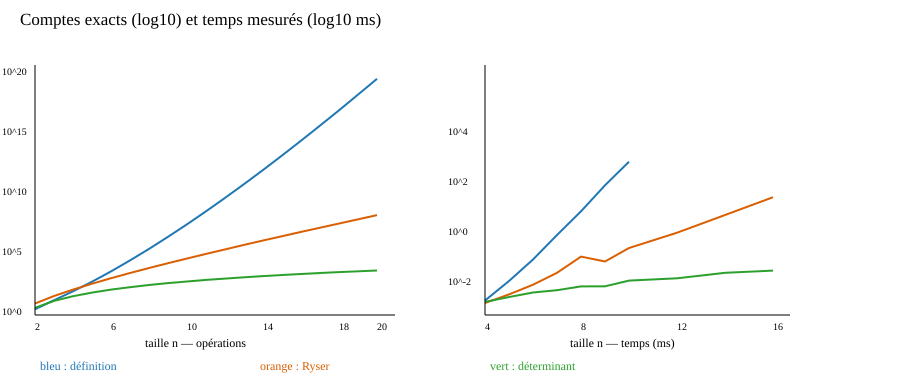

In [6]:
record Svg05(string Contenu);
Formatter.Register<Svg05>((v, w) => w.Write(v.Contenu), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg05), "image/svg+xml");
// Le graphique utilise les comptes et les temps produits ci-dessus ; aucune donnée n'est inventée.
string Courbe(IEnumerable<(double x, double y)> points, string couleur) => $"<polyline fill='none' stroke='{couleur}' stroke-width='2' points='{string.Join(" ", points.Select(p => $"{p.x:F1},{p.y:F1}"))}'/>";
var svg = new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='900' height='390' viewBox='0 0 900 390'><rect width='900' height='390' fill='white'/><text x='20' y='25' font-size='17'>Comptes exacts (log10) et temps mesurés (log10 ms)</text>");
var ns = Enumerable.Range(2, 19).ToArray();
Func<int, double> xp = n => 35 + (n - 2) * 19;
Func<double, double> yp = y => 315 - Math.Log10(Math.Max(y, 1)) * 12;
svg.Append(Courbe(ns.Select(n =>
{
    var v = OpsNaive(n);
    return (xp(n), yp((double)(v.mult + v.add)));
}), "#1f77b4"));
svg.Append(Courbe(ns.Select(n =>
{
    var v = OpsRyser(n);
    return (xp(n), yp(v.mult + v.add));
}), "#d95f02"));
svg.Append(Courbe(ns.Select(n =>
{
    var v = OpsGauss(n);
    return (xp(n), yp(v.mult + v.add));
}), "#2ca02c"));
Func<int, double> xt = n => 485 + (n - 4) * 24;
Func<double, double> yt = y => 235 - Math.Log10(Math.Max(y, 1e-6)) * 25;
svg.Append(Courbe(temps.Where(r => r.naive.HasValue).Select(r => (xt(r.n), yt(r.naive.Value))), "#1f77b4"));
svg.Append(Courbe(temps.Select(r => (xt(r.n), yt(r.ryser))), "#d95f02"));
svg.Append(Courbe(temps.Select(r => (xt(r.n), yt(r.det))), "#2ca02c"));
// Graduations logarithmiques et axes explicites rendent les deux échelles lisibles.
foreach (int k in new[]
{
    0,
    5,
    10,
    15,
    20
}

)
{
    double y = 315 - 12 * k;
    svg.Append($"<text x='2' y='{y:F1}' font-size='10'>10^{k}</text>");
}

foreach (int k in new[]
{
    -2,
    0,
    2,
    4
}

)
{
    double y = 235 - 25 * k;
    svg.Append($"<text x='448' y='{y:F1}' font-size='10'>10^{k}</text>");
}

foreach (int n in new[]
{
    2,
    6,
    10,
    14,
    18,
    20
}

)
    svg.Append($"<text x='{xp(n):F1}' y='330' font-size='10'>{n}</text>");
foreach (int n in new[]
{
    4,
    8,
    12,
    16
}

)
    svg.Append($"<text x='{xt(n):F1}' y='330' font-size='10'>{n}</text>");
svg.Append("<path d='M35 315H395 M35 65V315 M485 315H790 M485 65V315' stroke='black' fill='none'/><text x='145' y='347'>taille n — opérations</text><text x='570' y='347'>taille n — temps (ms)</text><text x='40' y='370' fill='#1f77b4'>bleu : définition</text><text x='260' y='370' fill='#d95f02'>orange : Ryser</text><text x='490' y='370' fill='#2ca02c'>vert : déterminant</text></svg>");
display(new Svg05(svg.ToString()));


La première vue représente les comptes sur une échelle logarithmique ; la seconde utilise les temps effectivement relevés par le chronomètre. La même couleur désigne l'algorithme ou sa bibliothèque de référence dans les deux panneaux. Les écarts de mise en œuvre et de charge machine rendent toute comparaison de temps moins générale que les formules de compte.

## 4. BosonSampling : la loi conditionnée $|\mathrm{perm}|^2$

On considère $n$ photons indiscernables entrant dans les $n$ premiers modes d'un interféromètre de $m$ modes, modélisé par une matrice unitaire $U$. Pour une sortie sans collision $T$ contenant $n$ modes distincts, son poids est $|\operatorname{perm}(U_{[n],T})|^2$. Le banc énumère toutes les $\binom mn$ sorties distinctes et **normalise leurs poids entre elles** : il mesure donc la loi conditionnée à l'absence de collision, et non la loi complète incluant toutes les occupations possibles.

Une unitaire de Haar est obtenue en factorisant par QR une matrice gaussienne complexe, puis en corrigeant les phases de la diagonale de $R$. MathNet effectue réellement cette factorisation ; la cellule vérifie numériquement $U^\dagger U=I$. La construction complète de la distribution paie une permanente par sortie une fois ; les tirages ultérieurs utilisent cette table. Ce coût est celui de cette énumération et ne constitue pas une borne pour tous les échantillonneurs classiques.

In [7]:
Complex[, ] Haar(int n, int seed)
{
    var r = new Random(seed);
    var z = new Complex[n, n];
    for (int i = 0; i < n; i++)
        for (int j = 0; j < n; j++)
            z[i, j] = new Complex(Normal(r), Normal(r)) / Math.Sqrt(2);
    // QR orthogonalise la matrice gaussienne complexe avant correction des phases.
    var qr = DenseMatrix.OfArray(z).QR();
    var q = qr.Q;
    var rr = qr.R;
    var u = new Complex[n, n];
    // Corriger la phase de chaque colonne de Q pour obtenir la loi de Haar.
    for (int j = 0; j < n; j++)
    {
        var d = rr[j, j];
        var phase = d.Magnitude == 0 ? Complex.One : d / d.Magnitude;
        for (int i = 0; i < n; i++)
            u[i, j] = q[i, j] * phase;
    }

    var mat = DenseMatrix.OfArray(u);
    double erreur = (mat.ConjugateTranspose() * mat - DenseMatrix.CreateIdentity(n)).FrobeniusNorm();
    if (erreur > 1e-10)
        throw new Exception("La matrice générée n'est pas unitaire");
    return u;
}

List<int[]> Sorties(int m, int n)
{
    var sorties = new List<int[]>();
    var choix = new int[n];
    void Visiter(int profondeur, int debut)
    {
        if (profondeur == n)
        {
            sorties.Add((int[])choix.Clone());
            return;
        }

        // Les indices croissants énumèrent chaque combinaison de modes une seule fois.
        for (int x = debut; x <= m - (n - profondeur); x++)
        {
            choix[profondeur] = x;
            Visiter(profondeur + 1, x + 1);
        }
    }

    Visiter(0, 0);
    return sorties;
}

(List<int[]> sorties, double[] p) Boson(Complex[, ] u, int n)
{
    int m = u.GetLength(0);
    var sorties = Sorties(m, n);
    var poids = new double[sorties.Count];
    for (int k = 0; k < sorties.Count; k++)
    {
        var a = new Complex[n, n];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++)
                a[i, j] = u[i, sorties[k][j]];
        // Le carré du module de la permanente donne le poids de cette sortie.
        var per = RyserRapide(a);
        poids[k] = per.Magnitude * per.Magnitude;
    }

    // La normalisation porte sur les seules sorties sans collision énumérées.
    double somme = poids.Sum();
    if (somme <= 0 || !double.IsFinite(somme))
        throw new Exception("Poids sans collision invalides");
    return (sorties, poids.Select(x => x / somme).ToArray());
}

double Entropie(double[] p) => -p.Where(x => x > 0).Sum(x => x * Math.Log2(x));
int Tirer(double[] cumul, Random r)
{
    double x = r.NextDouble();
    int i = Array.BinarySearch(cumul, x);
    return Math.Min(i >= 0 ? i : ~i, cumul.Length - 1);
}

double[] Cumul(double[] p)
{
    var c = new double[p.Length];
    double somme = 0;
    for (int i = 0; i < p.Length; i++)
    {
        somme += p[i];
        c[i] = somme;
    }

    // Forcer le dernier cumul à 1 évite un dépassement dû aux arrondis.
    c[c.Length - 1] = 1;
    return c;
}

var u0 = Haar(8, 103);
var petit = Boson(u0, 3);
Console.WriteLine($"n=3, m=8 : {petit.p.Length} sorties, uniforme conditionnelle={1.0 / petit.p.Length:F4}");
foreach (int i in Enumerable.Range(0, petit.p.Length).OrderByDescending(i => petit.p[i]).Take(5))
    Console.WriteLine($"  modes ({string.Join(",", petit.sorties[i])}) : p={petit.p[i]:F4}, {petit.p[i] * petit.p.Length:F1}× l'uniforme");
Console.WriteLine($"Entropie={Entropie(petit.p):F3} bits, maximum={Math.Log2(petit.p.Length):F3}");


n=3, m=8 : 56 sorties, uniforme conditionnelle=0.0179


  modes (1,2,3) : p=0.0769, 4.3× l'uniforme


  modes (0,2,6) : p=0.0651, 3.6× l'uniforme


  modes (0,3,4) : p=0.0480, 2.7× l'uniforme


  modes (0,3,6) : p=0.0425, 2.4× l'uniforme


  modes (0,6,7) : p=0.0416, 2.3× l'uniforme


Entropie=5.280 bits, maximum=5.807



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you ma

### Lecture — interférence et conditionnement

La sortie affiche les cinq modes les plus probables sur 56 configurations sans collision, leur rapport à l'uniforme et l'entropie de la loi normalisée. Sur ce tirage .NET, les poids des deux premières issues sont 0,0769 et 0,0651, contre 1/56 ≈ 0,0179 ; l'entropie est 5,280 bits pour un maximum de 5,807. Les interférences font généralement varier les poids entre issues ; les valeurs précises changent avec la matrice de Haar et le générateur. L'entropie maximale affichée est celle d'une loi uniforme **sur ces 56 issues conditionnées**, pas sur toutes les sorties physiques possibles.

In [8]:
// Conserver les deux grands bancs du source : 924 et 12 870 issues.
(List<int[]> sorties, double[] p) loi612 = default;
foreach (var(n, m)in new[]
{
    (6, 12),
    (8, 16)
}

)
{
    var u = Haar(m, 100 + n);
    var chrono = System.Diagnostics.Stopwatch.StartNew();
    var loi = Boson(u, n);
    chrono.Stop();
    Console.WriteLine($"n={n}, m={m}: {loi.p.Length} sorties, pmax={loi.p.Max():F5}, entropie={Entropie(loi.p):F3}/{Math.Log2(loi.p.Length):F3}, construction={chrono.Elapsed.TotalMilliseconds:F1} ms");
    if (n == 6)
        loi612 = loi;
}

var cumul612 = Cumul(loi612.p);
var sampler = new Random(7);
foreach (int N in new[]
{
    2000,
    20000,
    200000
}

)
{
    var comptes = new int[loi612.p.Length];
    for (int k = 0; k < N; k++)
        comptes[Tirer(cumul612, sampler)]++;
    // La moitié de la distance L1 compare fréquence empirique et loi exacte.
    double tv = 0;
    for (int k = 0; k < comptes.Length; k++)
        tv += Math.Abs((double)comptes[k] / N - loi612.p[k]);
    Console.WriteLine($"N={N} : distance en variation totale={tv / 2:F4}");
}


n=6, m=12: 924 sorties, pmax=0.00930, entropie=9.167/9.852, construction=11.2 ms


n=8, m=16: 12870 sorties, pmax=0.00091, entropie=12.914/13.652, construction=872.7 ms


N=2000 : distance en variation totale=0.2400


N=20000 : distance en variation totale=0.0774


N=200000 : distance en variation totale=0.0240


### Lecture — construire puis tirer

Les deux tailles conservent 924 et 12 870 sorties sans collision. Le temps affiché mesure la construction de **cette table** sur la machine ; il ne s'agit pas d'un coût par tirage ni d'une estimation de tous les algorithmes. La distance en variation totale compare l'histogramme à la table exacte déjà construite : elle vaut ici 0,2400, 0,0774 puis 0,0240 pour 2 000, 20 000 puis 200 000 tirages. Les entropies mesurées sont 9,167 bits sur 9,852 pour (6,12), puis 12,914 sur 13,652 pour (8,16). Une fluctuation ponctuelle reste possible, même si l'échantillonnage converge en loi lorsque le nombre de tirages augmente.

## Exercice 2 — Marginales d'une sortie sans collision

Pour chaque mode $j$, calculer $P(j\in T)=\sum_{T\ni j}p(T)$ à partir de la table exacte $(6,12)$, puis comparer aux marginales d'un échantillon de 20 000 sorties. Chaque sortie contient six modes : la somme des douze marginales vaut donc 6.

Pour une unitaire de Haar **fixée**, les marginales n'ont aucune raison d'être exactement plates ; la symétrie $n/m$ concerne la moyenne sur l'ensemble des unitaires de Haar. L'écart à $n/m$ décrit cette réalisation conditionnée, tandis que l'écart échantillon–exact mesure le bruit de tirage. Le contrôle vérifie chaque marginale contre une somme indépendante et pas seulement leur somme totale.

In [9]:
double[] Marginales(List<int[]> sorties, double[] probabilites, int m)
{
    // TODO : additionner les probabilités des sorties contenant chaque mode.
    return null;
}

var ex2 = Marginales(loi612.sorties, loi612.p, 12);
if (ex2 == null)
    Console.WriteLine("Exercice 2 à compléter");
else
{
    if (ex2.Length != 12 || ex2.Any(x => !double.IsFinite(x) || x < 0 || x > 1))
        throw new Exception("Marginales invalides");
    for (int j = 0; j < 12; j++)
    {
        int mode = j;
        double attendu = Enumerable.Range(0, loi612.p.Length).Where(k => loi612.sorties[k].Contains(mode)).Sum(k => loi612.p[k]);
        if (Math.Abs(ex2[j] - attendu) > 1e-10)
            throw new Exception("Marginale exacte incorrecte");
    }

    var r = new Random(19);
    var frequencesSorties = new double[loi612.p.Length];
    var comptageModes = new int[12];
    for (int i = 0; i < 20000; i++)
    {
        int k = Tirer(cumul612, r);
        frequencesSorties[k]++;
        foreach (int j in loi612.sorties[k])
            comptageModes[j]++;
    }

    for (int k = 0; k < frequencesSorties.Length; k++)
        frequencesSorties[k] /= 20000;
    var echantillon = Marginales(loi612.sorties, frequencesSorties, 12);
    if (echantillon == null || echantillon.Length != 12 ||
        echantillon.Any(x => !double.IsFinite(x) || x < 0 || x > 1))
        throw new Exception("Marginales échantillonnées invalides");
    for (int j = 0; j < 12; j++)
        if (Math.Abs(echantillon[j] - comptageModes[j] / 20000.0) > 1e-10)
            throw new Exception("Marginale échantillonnée incorrecte");
    Console.WriteLine($"Écart exact à n/m={ex2.Max(x => Math.Abs(x - 0.5)):F4} ; écart échantillon à n/m={echantillon.Max(x => Math.Abs(x - 0.5)):F4} ; écart échantillon/exact={Enumerable.Range(0, 12).Max(j => Math.Abs(echantillon[j] - ex2[j])):F4} (20000 tirages)");
}


Exercice 2 à compléter


## 5. Extrapoler l'énumération sans la prendre pour une borne

Pour $(n,m)=(10,20),(12,24),\ldots,(20,40)$, on multiplie le nombre de sorties $\binom mn$ par le compte Ryser utilisé plus haut. La conversion hypothétique à $10^{12}$ opérations par seconde est une **extrapolation**, pas une mesure. Elle suppose une opération par unité de débit, ignore la mémoire et ne concerne que l'énumération complète de cette loi conditionnée.

In [10]:
// Multiplier sorties et opérations donne le coût de cette énumération, pas une borne générale.
BigInteger Choisir(int n, int k)
{
    BigInteger c = 1;
    for (int i = 1; i <= k; i++)
        c = c * (n - k + i) / i;
    return c;
}

var murs = new List<BigInteger>();
foreach (int n in new[]
{
    10,
    12,
    14,
    16,
    18,
    20
}

)
{
    int m = 2 * n;
    var r = OpsRyser(n);
    BigInteger nombre = Choisir(m, n);
    BigInteger ops = nombre * (r.mult + r.add);
    murs.Add(ops);
    Console.WriteLine($"n={n}, m={m} : {nombre} sorties × {r.mult + r.add} opérations = {ops} ; à 1 TFLOP/s ~{(double)ops / 1e12:G4} s (extrapolé)");
}

for (int i = 1; i < murs.Count; i++)
    Console.WriteLine($"Facteur par deux photons : {(double)murs[i] / (double)murs[i - 1]:F2}");


n=10, m=20 : 184756 sorties × 51209 opérations = 9461170004 ; à 1 TFLOP/s ~0.009461 s (extrapolé)


n=12, m=24 : 2704156 sorties × 294923 opérations = 797517799988 ; à 1 TFLOP/s ~0.7975 s (extrapolé)


n=14, m=28 : 40116600 sorties × 1605645 opérations = 64413018207000 ; à 1 TFLOP/s ~64.41 s (extrapolé)


n=16, m=32 : 601080390 sorties × 8388623 opérations = 5042236784402970 ; à 1 TFLOP/s ~5042 s (extrapolé)


n=18, m=36 : 9075135300 sorties × 42467345 opérations = 385396901706778500 ; à 1 TFLOP/s ~3.854E+05 s (extrapolé)


n=20, m=40 : 137846528820 sorties × 209715219 opérations = 28908514979876111580 ; à 1 TFLOP/s ~2.891E+07 s (extrapolé)


Facteur par deux photons : 84.29


Facteur par deux photons : 80.77


Facteur par deux photons : 78.28


Facteur par deux photons : 76.43


Facteur par deux photons : 75.01


### Lecture — ce qui croît dans ce protocole

La sortie donne à titre d'exemple environ $6,44\times10^{13}$ opérations pour $(14,28)$ et des facteurs par tranche de deux photons allant ici de 84,29 à 75,01. Lorsque $m=2n$, deux facteurs augmentent : le nombre $\binom{2n}{n}$ de sorties et le coût de la permanente par sortie. Les facteurs imprimés décrivent leur produit pour les tailles choisies. Une extrapolation de cette méthode met en évidence son coût ; elle ne prouve pas qu'aucune autre méthode exacte ou approchée ne pourrait échantillonner plus efficacement.

## Exercice 3 — La bascule mesurée

Mesurer définition et Ryser mémorisé sur des matrices de tailles 2 à 10 avec cinq répétitions chacune. Renvoyer la première taille où Ryser est plus rapide ; s'il n'y en a pas, retourner `null`. La mesure réelle dépend de la machine : il n'est pas garanti que le rapport croisse à chaque taille. La garde teste aussi une petite série synthétique où la première bascule et l'absence de bascule sont connues.

In [11]:
int? PremiereBascule(int[] tailles, double[] definition, double[] ryser)
{
    // TODO : retourner la première taille dont le temps Ryser est strictement inférieur.
    return null;
}

var testBascule = PremiereBascule(new[] { 2, 3, 4 }, new[] { 1.0, 2.0, 5.0 }, new[] { 2.0, 3.0, 4.0 });
if (testBascule == null)
    Console.WriteLine("Exercice 3 à compléter");
else
{
    if (testBascule != 4 || PremiereBascule(new[] { 2, 3 }, new[] { 1.0, 1.0 }, new[] { 2.0, 2.0 }) != null)
        throw new Exception("Première bascule incorrecte");
    var ns = Enumerable.Range(2, 9).ToArray();
    var na = new List<double>();
    var ry = new List<double>();
    foreach (int n in ns)
    {
        var a = MatriceNormale(n, new Random(200 + n));
        na.Add(MinimumTemps(() => PermanenteNaive(a), 5));
        ry.Add(MinimumTemps(() => RyserRapide(a), 5));
    }

    int? observe = PremiereBascule(ns, na.ToArray(), ry.ToArray());
    int? attendu = Enumerable.Range(0, ns.Length).Where(i => ry[i] < na[i]).Select(i => (int? )ns[i]).FirstOrDefault();
    if (observe != attendu)
        throw new Exception("Bascule incohérente avec les temps mesurés");
    Console.WriteLine($"Première bascule observée : {observe?.ToString() ?? "aucune"} (cinq essais par taille)");
}


Exercice 3 à compléter


## 6. Ce que la mesure ne prouve pas

| Affirmation | Statut dans ce carnet |
|---|---|
| Comptages de la définition, Ryser et Gauss ; comparaisons numériques | Mesurés sur les algorithmes et tailles ci-dessus |
| Permanente 0/1 et couplages sur les exemples | Vérifiés par deux énumérations sur les matrices tirées |
| Difficulté #P de la permanente exacte | Rapportée par le source Python, attribuée à Valiant ; non démontrée ici |
| Algorithme d'approximation pour les matrices non négatives | Rapporté par le source Python, attribué à Jerrum–Sinclair–Vigoda ; conditions hors de ce banc |
| Conséquences de complexité de l'échantillonnage BosonSampling | Rapportées par le source, avec les hypothèses pertinentes ; non démontrées par la table finie |
| Borne inférieure pour tout algorithme classique d'échantillonnage | Absente de ce carnet |

Le source rappelle que l'approximation change de statut selon le domaine : il rapporte un FPRAS pour les matrices non négatives et une difficulté liée notamment aux signes ou phases complexes dans les formulations qu'il cite. Ces phrases ne remplacent ni les hypothèses précises des théorèmes ni une analyse de l'erreur de notre échantillonnage.

Le Python relevait aussi, le 2026-09-19 sur la branche master, après lecture de l’arborescence `Mathlib/LinearAlgebra/Matrix/` et du fichier `Permanent.lean`, l'existence de `Matrix.permanent` dans `Mathlib/LinearAlgebra/Matrix/Permanent.lean` sous sa forme par permutations, $\sum_{\sigma}\prod_i M_{\sigma(i),i}$, et distinguait cette définition de la formule de Ryser et de la couche de complexité. Il décrivait quelques lemmes algébriques disponibles et une théorie du déterminant plus développée ; définir la permanente n'est pas encore prouver l'algorithme de Ryser ni formaliser #P. Ce relevé est rapporté comme historique, sans nouvelle recherche exhaustive dans Mathlib pour ce port.
Le relevé d’absence de Ryser est borné à cette arborescence : le Python précise qu’une recherche exhaustive du code demandait une session GitHub. Il rapportait le fichier de M. Firsching (2024), une dizaine de lemmes et un dossier consacré au déterminant.


## À retenir

1. **Le signe différencie permanente et déterminant.** Une matrice 0/1 fait de la permanente un compteur de couplages parfaits ; nos deux petits graphes le vérifient indépendamment.
2. **Une définition n'est pas un coût minimal prouvé.** Les formules $n!$, $2^n$ et cubique décrivent les algorithmes instrumentés ; les chronos dépendent de leurs implémentations.
3. **La loi est conditionnée aux sorties sans collision.** La construction paie une permanente par combinaison, puis les tirages échantillonnent la table déjà calculée.
4. **Une extrapolation garde son hypothèse.** Les facteurs du tableau concernent $m=2n$ et cette énumération ; ils ne sont pas une borne sur tout échantillonneur.
5. **Les marginales d'une unitaire fixée peuvent être non uniformes.** $n/m$ est un repère symétrique en moyenne sur les unitaires de Haar, pas une égalité imposée pour une réalisation.

## Vérifiez votre compréhension

1. Pourquoi l'échantillonnage de la table peut-il converger alors que sa construction emploie des permanentes coûteuses ?
2. Quels facteurs expliquent la croissance du coût de l'énumération quand $m=2n$ ?
3. Que distingue le relevé historique de `Matrix.permanent` entre définition, algorithme et théorie de complexité ?

<details><summary>Éléments de réponse</summary>

1. La table a déjà été calculée ; les tirages ultérieurs ne recalculent pas les permanentes. Cela ne prouve pas qu'une table complète soit nécessaire pour tout échantillonneur.
2. Le nombre de combinaisons et le coût Ryser de chaque sous-matrice croissent simultanément.
3. Une définition mathématique dans une bibliothèque n'implique ni une implémentation rapide, ni la formalisation des énoncés de complexité associés.
</details>

Le cadrage philosophique attribué par le Python à Aaronson rappelle que la complexité, au-delà de la calculabilité, compte pour interpréter ce qui est faisable ; cette perspective motive la mesure et ne démontre pas les affirmations de complexité.

## Pour aller plus loin

[Source Python](Complexity-05b-AaronsonArkhipov-PermanenteBosonSampling-Python.ipynb) · [05 — permanente et comptage](Complexity-05-CountingHarder-Permanent-Python.ipynb) · [06 — simulation classique](Complexity-06-Simuler-Circuit-Quantique-Classiquement-Python.ipynb) · [06b — circuits stabilisateurs](Complexity-06b-AaronsonGottesman-Dequantification-Python.ipynb) · [ANALYSE-12 — compter les couplages parfaits](../../SymbolicAI/Lean/Analyse/ANALYSE-12-Comptage-Matching-Lean-Python.ipynb).

**Références rapportées par le Python** (publications non consultées pour ce port) :

- Aaronson et Arkhipov (2013), « The Computational Complexity of Linear Optics », *Theory of Computing* 9(1), 143–252 (prépublication 2011).
- Valiant (1979), « The Complexity of Computing the Permanent », *Theoretical Computer Science* 8(2), 189–201.
- Ryser (1963), « Combinatorial Properties of Matrices of Zeros and Ones », *Canadian Journal of Mathematics* 13, 341–347.
- Jerrum, Sinclair et Vigoda (2004), « A Polynomial-time Approximation Algorithm for the Permanent of a Matrix with Nonnegative Entries », *JACM* 51(4), 671–697.
- Mezzadri (2007), « How to Generate Random Matrices from the Classical Compact Groups », *Notices of the AMS* 54(5), 592–604.
- Aaronson (2013), « Why Philosophers Should Care About Computational Complexity », dans *Computability: Turing, Gödel, Church, and Beyond*, MIT Press (prépublication 2011).
